# EDA-Schema ASAP7 — v2.1 BPBF

Per-PDK notebook for **ASAP7 7nm (ASAP7)** (`dataset/asap7_v2.1_bpbf`). Sibling notebooks: `Analysis-NG45.ipynb`, `Analysis-SKY130.ipynb`, `Analysis-IHP130.ipynb`, `Analysis-ASAP7.ipynb`.

v2.1 is not the v2.0 sweep (~1944 flows). It is the **barely-pass / barely-fail** cut of the same 18 IWLS designs:

| | v2.1 | v2.0 counterpart |
|---|---|---|
| Barely pass (BP) | `*-000001` | `*-000014` |
| Barely fail (BF) | `*-000002` | `*-000023` |
| Aspect ratio | 1.0 | 1.0 |
| Core utilization | 40% | 40% |
| Swept knob | target clock period | same index in the old sweep |

BP is the slowest clock that still meets timing at `final` (on most PDKs). BF is the next tighter clock, which should violate. The last section overlays v2.0 14/23 on the same designs to see what moved: the clock, the slack, or the physical netlist.

1. [Load](#1-load-v21)
2. [BP / BF at final](#2-barely-pass--barely-fail)
3. [PPA](#3-ppa-at-final)
4. [Across design stages](#4-across-design-stages)
5. [vs v2.0 — OpenROAD / ORFS shift](#5-vs-v20--openroad--orfs-shift)


In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from eda_schema.dataset import Dataset
from eda_schema.db import ParquetDB
from eda_schema.entity import DesignStages

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.05)

RESULTS = Path("../results")
RESULTS.mkdir(parents=True, exist_ok=True)

PDK = "ASAP7"
PDK_DIR = "asap7"
FINAL_STAGE = "final"
ASAP7_PS_TO_NS = PDK == "ASAP7"
V21_DIR = Path(os.environ.get("EDA_SCHEMA_V2_1_DATASET") / f"{PDK_DIR}_v2.1_bpbf"
V2_DIR = Path(os.environ.get("EDA_SCHEMA_V2_DATASET")) / PDK_DIR

METRIC_COLS = ["total_area", "total_power", "worst_slack",
               "total_negative_slack", "net_length", "no_of_violating_endpoints"]
METRIC_LABELS = ["Area (µm²)", "Power (µW)", "WNS (ns)",
                 "TNS (ns)", "Wirelength (µm)", "Violating endpoints"]

def load_dump(path: Path) -> pd.DataFrame:
    ds = Dataset(ParquetDB(str(path)))
    df = (
        ds.db.get_table_data("design_flows")
        .merge(ds.db.get_table_data("constraints"), on="flow_id")
        .merge(ds.db.get_table_data("netlists"), on="flow_id")
        .merge(ds.db.get_table_data("cell_metrics"), on=["flow_id", "stage"])
        .merge(ds.db.get_table_data("area_metrics"), on=["flow_id", "stage"])
        .merge(ds.db.get_table_data("power_metrics"), on=["flow_id", "stage"])
        .merge(ds.db.get_table_data("timing_metrics"), on=["flow_id", "stage"])
    )
    df["stage"] = pd.Categorical(df["stage"], categories=DesignStages.tolist(), ordered=True)
    df["flow_index"] = df["flow_id"].str.split("-").str[-1].astype(int)
    routed = df["stage"].isin(["detailed_route", "final"])
    df["net_length"] = np.where(routed, df["total_wirelength"], df["total_hpwl"])
    df["SCPR"] = 100.0 * df["worst_slack"] / df["clock_period"]
    return df

def label_bpbf(df: pd.DataFrame, bp: int, bf: int) -> pd.DataFrame:
    out = df.copy()
    out["clock_class"] = pd.Categorical(
        np.select([out.flow_index == bp, out.flow_index == bf], ["BP", "BF"], default=None),
        categories=["BF", "BP"], ordered=True,
    )
    return out.dropna(subset=["clock_class"])


## 1. Load v2.1

Parquet dump: `dataset/asap7_v2.1_bpbf`. One row per `(flow_id, stage)` after joining flows, constraints, netlist, cells, area, power, and timing.

Wirelength is the netlist total (`total_wirelength` after detailed route, otherwise HPWL). Per-net tables are left to the old v2 notebooks — they are slow and not needed for this cut.
ASAP7 OpenROAD clocks are picoseconds; this notebook converts v2.1 TCP to ns (`/1000`) so it lines up with v2.0.


In [2]:
df = label_bpbf(load_dump(V21_DIR), bp=1, bf=2)
if ASAP7_PS_TO_NS:
    df["clock_period"] = df["clock_period"] / 1000.0
    df["SCPR"] = 100.0 * df["worst_slack"] / df["clock_period"]
final = df[df.stage == FINAL_STAGE].copy()


## 2. Barely pass / barely fail

**SCPR** = `100 × WNS / TCP` (percent of the period). Positive SCPR is timing-clean; a few percent is “barely.”

Each design has exactly two `final` points. The strip is the whole dump. The bar on the right is the timing-clean count (WNS ≥ 0). With a correct TT liberty dump, BF should violate.


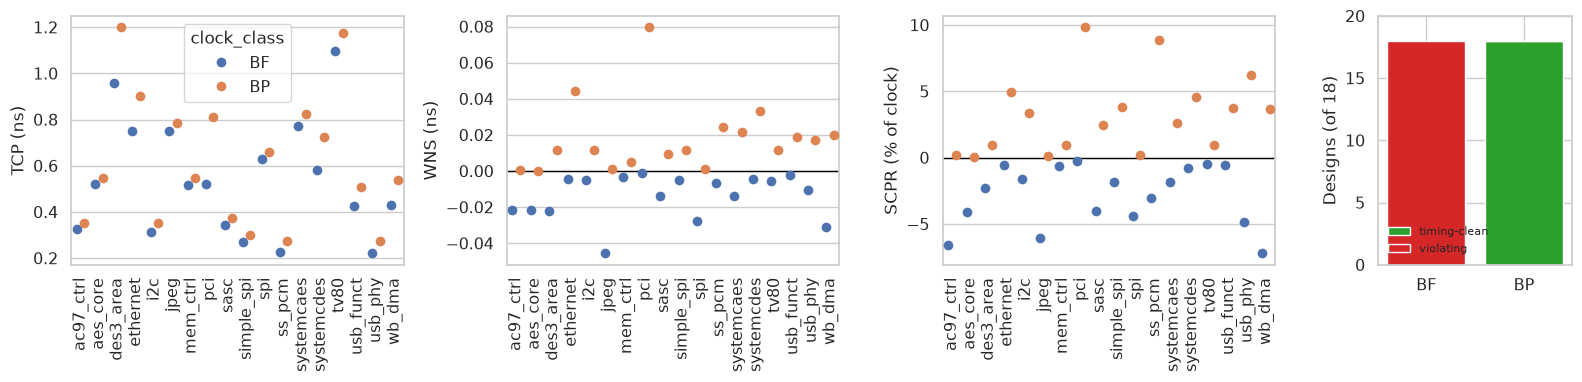

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1.2, 1.2, 1.2, 0.7]})
order = sorted(final.design.unique())
for ax, col, label in zip(axes[:3], ["clock_period", "worst_slack", "SCPR"],
                            ["TCP (ns)", "WNS (ns)", "SCPR (% of clock)"]):
    sns.stripplot(data=final, x="design", y=col, hue="clock_class",
                  order=order, hue_order=["BF", "BP"], dodge=True, ax=ax, size=7)
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=90)
    if col in ("worst_slack", "SCPR"):
        ax.axhline(0, color="black", linewidth=1)
    if ax is not axes[0]:
        ax.get_legend().remove()
pass_tab = (final.assign(clean=final.worst_slack >= 0)
            .groupby("clock_class", observed=False)["clean"]
            .agg(n="size", clean="sum"))
x = np.arange(2)
cls = ["BF", "BP"]
clean = [int(pass_tab.loc[c, "clean"]) if c in pass_tab.index else 0 for c in cls]
fail = [int(pass_tab.loc[c, "n"] - pass_tab.loc[c, "clean"]) if c in pass_tab.index else 0 for c in cls]
axes[3].bar(x, clean, color="#2ca02c", label="timing-clean")
axes[3].bar(x, fail, bottom=clean, color="#d62728", label="violating")
axes[3].set_xticks(x)
axes[3].set_xticklabels(cls)
axes[3].set_ylabel("Designs (of 18)")
axes[3].set_ylim(0, 20)
axes[3].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_bpbf_tcp_wns_scpr.png", dpi=200, bbox_inches="tight")
plt.show()


## 3. PPA at final

Two points per design. Area / power / wirelength use a log axis because the 18 circuits span more than a decade.
A vertical pair (BP vs BF) is the effect of tightening the clock on that design; the spread across designs is circuit size, not the PDK.


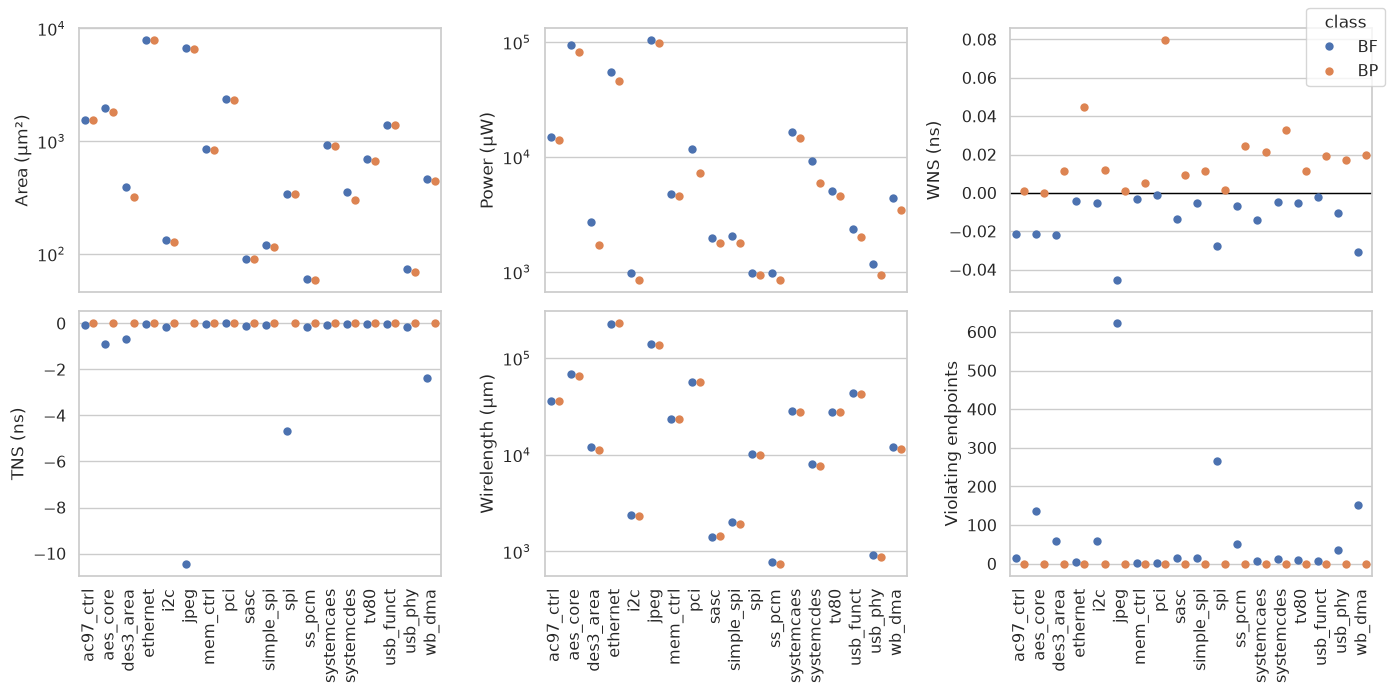

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
order = sorted(final.design.unique())
handles = labels = None
for ax, col, label in zip(axes.ravel(), METRIC_COLS, METRIC_LABELS):
    sns.stripplot(data=final, x="design", y=col, hue="clock_class",
                  order=order, hue_order=["BF", "BP"], dodge=True, ax=ax, size=6)
    ax.set_xlabel("")
    ax.set_ylabel(label)
    if col in ("total_area", "total_power", "net_length"):
        ax.set_yscale("log")
    if col == "worst_slack":
        ax.axhline(0, color="black", linewidth=1)
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()
for ax in axes[0]:
    ax.tick_params(axis="x", labelbottom=False)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=90)
fig.legend(handles, labels, loc="upper right", title="class")
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_ppa_strip_2x3.png", dpi=200, bbox_inches="tight")
plt.show()


## 4. Across design stages

Mean over the 18 designs at each OpenROAD stage, BP vs BF. Same six metrics as the PPA strip: area, power, WNS, TNS, wirelength, violating endpoints.

Floorplan HPWL is empty in this dump, so wirelength starts at global place.


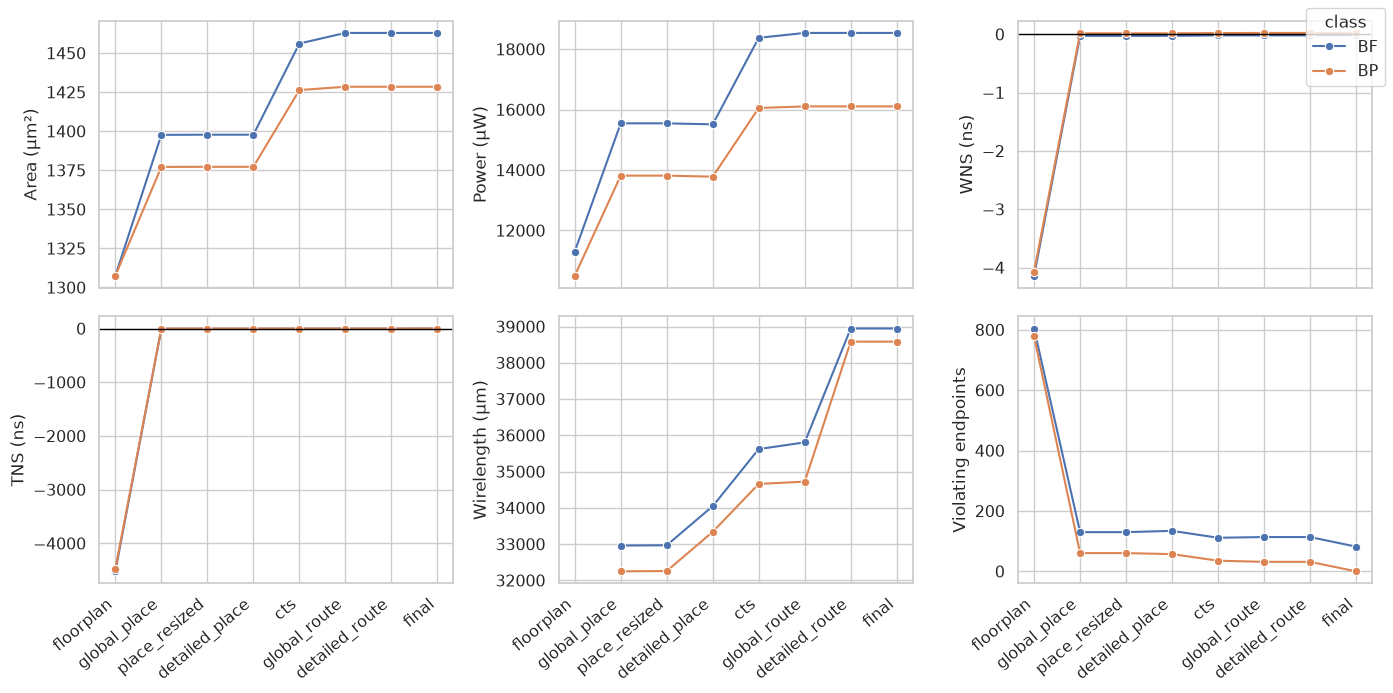

In [5]:
stage_mean = (
    df.groupby(["clock_class", "stage"], observed=False)[METRIC_COLS]
    .mean()
    .reset_index()
)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
handles = labels = None
for ax, col, label in zip(axes.ravel(), METRIC_COLS, METRIC_LABELS):
    sns.lineplot(data=stage_mean, x="stage", y=col, hue="clock_class",
                 hue_order=["BF", "BP"], marker="o", ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(label)
    if col in ("worst_slack", "total_negative_slack"):
        ax.axhline(0, color="black", linewidth=1)
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()
for ax in axes[0]:
    ax.tick_params(axis="x", labelbottom=False)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=40)
    plt.setp(ax.get_xticklabels(), ha="right")
fig.legend(handles, labels, loc="upper right", title="class")
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_stage_mean_2x3.png", dpi=200, bbox_inches="tight")
plt.show()


## 5. vs v2.0 — OpenROAD / ORFS shift

EDA-Schema **V2** was generated with ORFS commit `a50fb65`. **V2.1** regenerates the BP/BF subset with ORFS commit `c2c8aee`, designs retuned near timing closure.
This section answers: on this PDK, by how much does the regenerated OpenROAD flow **improve or degrade** final QoR?

Pairing (same AR = 1, util = 40%):

- v2.1 `000001` ↔ v2.0 `000014`
- v2.1 `000002` ↔ v2.0 `000023`

Bars below keep the **BP / BF split**. The improve/degrade summary after that pools all 36 pairs.

Metrics: **area, power, wirelength, WNS, TNS**. TCP is context only — v2.1 often retargets the clock.

Improve / degrade convention: area, power, wirelength → lower is better; WNS, TNS → higher is better.

v2.0 dump: `asap7` under `$EDA_SCHEMA_V2_DATASET`.

**ASAP7 units.** OpenROAD ASAP7 SDC is picoseconds. v2.0 stored ns; v2.1 stored ps. TCP is converted to ns here before deltas.


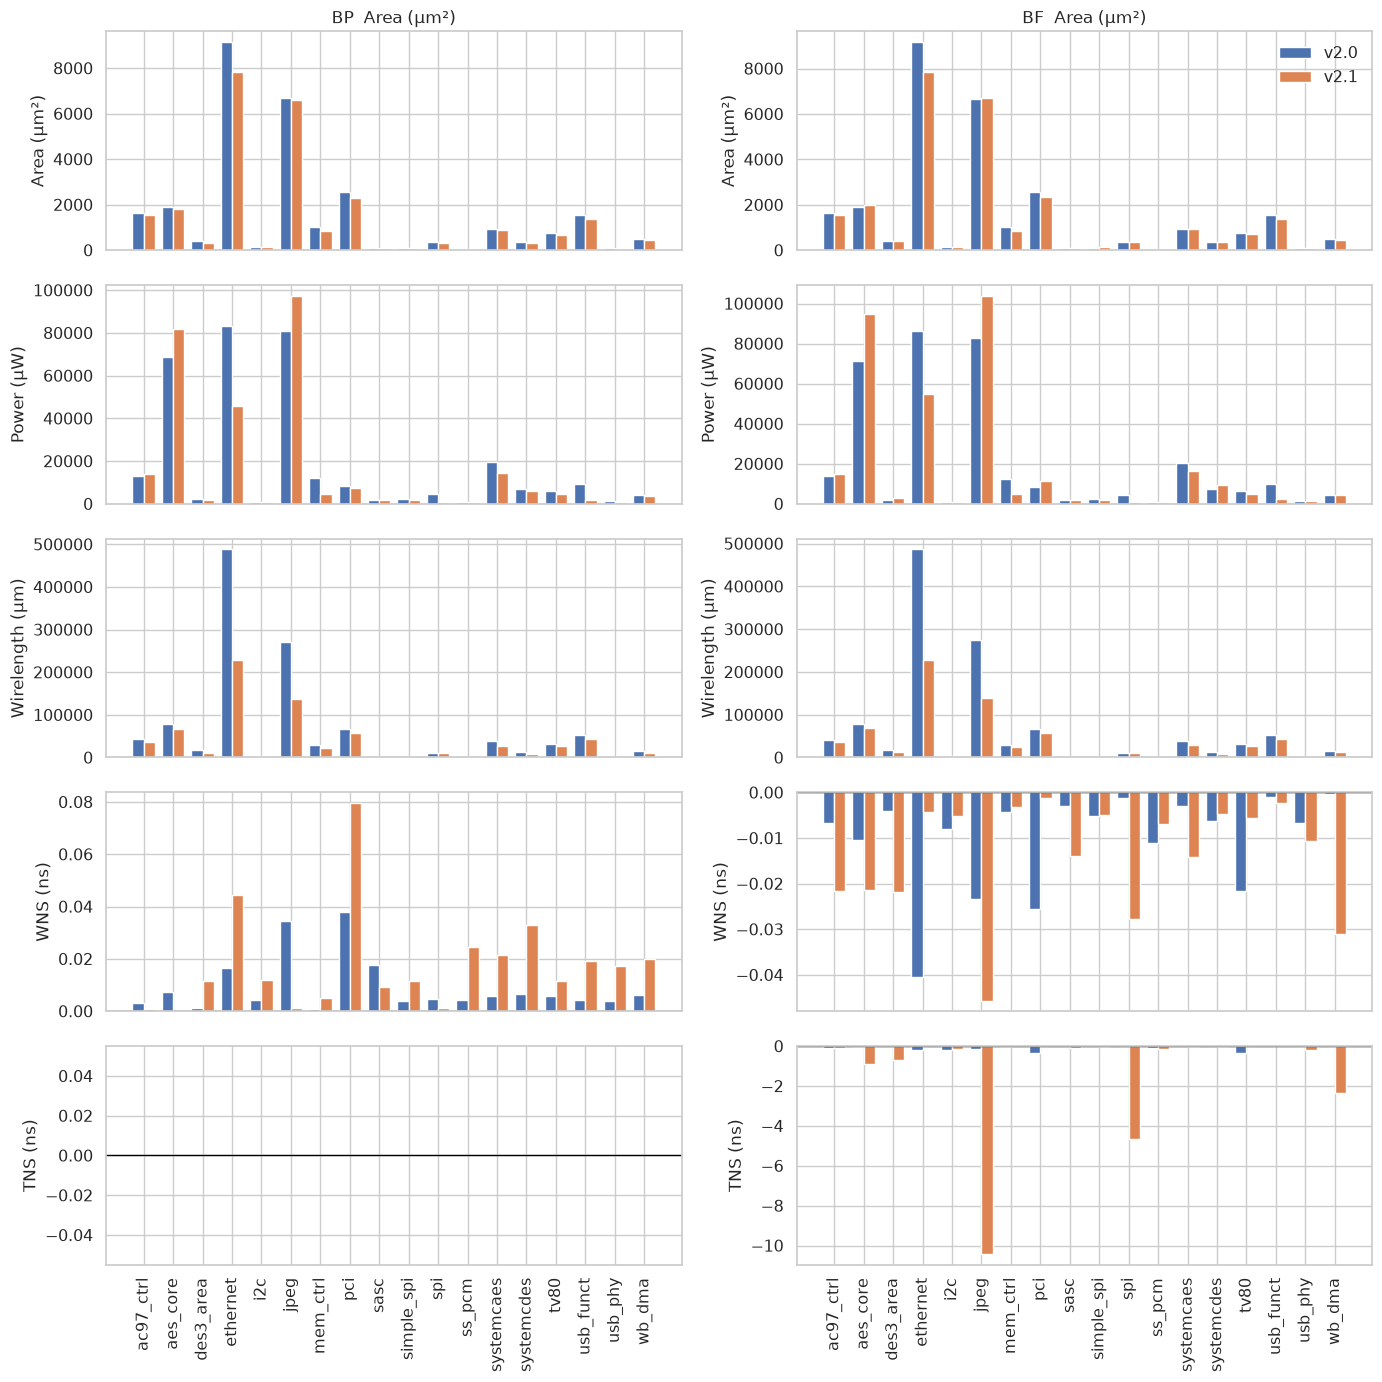

In [6]:
from IPython.display import display

assert V2_DIR.exists(), f"v2.0 dump not found: {V2_DIR}"
v2 = label_bpbf(load_dump(V2_DIR), bp=14, bf=23)
v2f = v2[v2.stage == FINAL_STAGE].copy()

keys = ["design", "clock_class"]
metrics = ["clock_period", "worst_slack", "total_negative_slack",
           "total_area", "total_power", "net_length"]
cmp = (v2f.set_index(keys)[metrics].add_prefix("v20_")
       .join(final.set_index(keys)[metrics].add_prefix("v21_"), how="inner")
       .reset_index())

order = sorted(cmp.design.unique())
x = np.arange(len(order))
width = 0.38
bar_metrics = [
    ("total_area", "Area (µm²)"),
    ("total_power", "Power (µW)"),
    ("net_length", "Wirelength (µm)"),
    ("worst_slack", "WNS (ns)"),
    ("total_negative_slack", "TNS (ns)"),
]
fig, axes = plt.subplots(len(bar_metrics), 2, figsize=(14, 2.8 * len(bar_metrics)), sharex=True)
for row, (metric, ylabel) in enumerate(bar_metrics):
    for col, cls in enumerate(["BP", "BF"]):
        ax = axes[row, col]
        sub = cmp[cmp.clock_class == cls].set_index("design").loc[order]
        ax.bar(x - width / 2, sub[f"v20_{metric}"], width, label="v2.0", color="#4c72b0")
        ax.bar(x + width / 2, sub[f"v21_{metric}"], width, label="v2.1", color="#dd8452")
        ax.set_title(f"{cls}  {ylabel}" if row == 0 else "")
        ax.set_ylabel(ylabel)
        if metric in ("worst_slack", "total_negative_slack"):
            ax.axhline(0, color="black", linewidth=1)
        if row == 0 and col == 1:
            ax.legend(frameon=False)
        if row == len(bar_metrics) - 1:
            ax.set_xticks(x)
            ax.set_xticklabels(order, rotation=90)
        else:
            ax.tick_params(axis="x", labelbottom=False)
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_v20_vs_v21_bars.png", dpi=200, bbox_inches="tight")
plt.show()


### Improve / degrade summary

Pooled over all 36 paired flows — **no BP/BF split**. **Δ** = `v2.1 − v2.0`. **%** = `100 × Δ / |v2.0|` (omit when v2.0 = 0).

WNS/TNS **%** is unstable when slack is near zero — use the absolute Δ for timing; use % for area / power / wirelength.


,metric,better,verdict,median_Δ,mean_Δ,std_Δ,min_Δ,max_Δ,median_%,mean_%,std_%,min_%,max_%,n
0,Area,lower,improve,-36.000,-124.417,297.803,-1316.000,93.000,-4.822,-6.052,6.216,-19.697,4.947,36
1,Power,lower,improve,-244.500,-1065.139,10688.763,-37400.000,23900.000,-10.704,-13.626,32.622,-78.802,39.591,36
2,Wirelength,lower,improve,-4596.823,-25715.456,64009.040,-259610.091,28.319,-15.598,-19.497,14.046,-53.180,2.018,36
3,WNS,higher,improve,0.002,0.003,0.017,-0.033,0.042,30.084,-315.574,1963.117,-11628.302,720.605,36
4,TNS,higher,flat,0.000,-0.512,1.870,-10.318,0.338,-591.941,-27967.266,83982.354,-353481.764,99.640,36
5,TCP (context),context,retarget,-0.030,-0.094,0.124,-0.350,0.150,-8.167,-12.148,14.509,-39.412,20.000,36


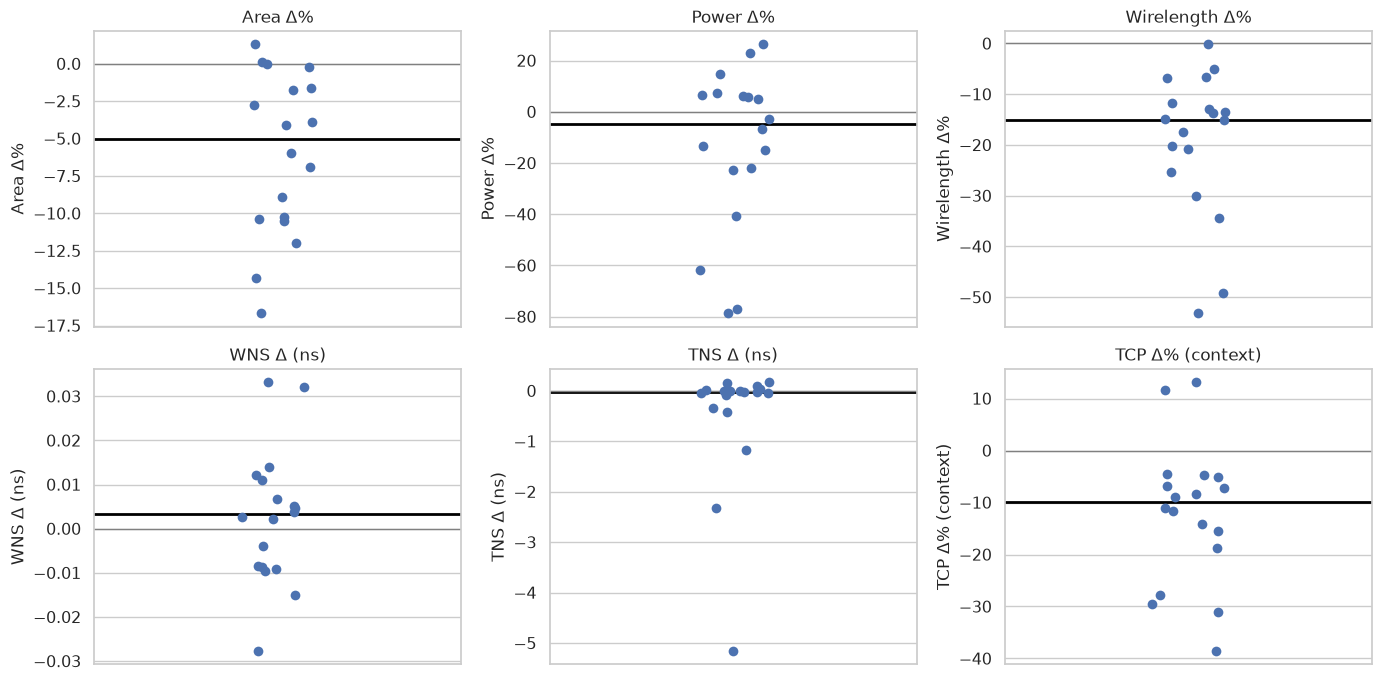

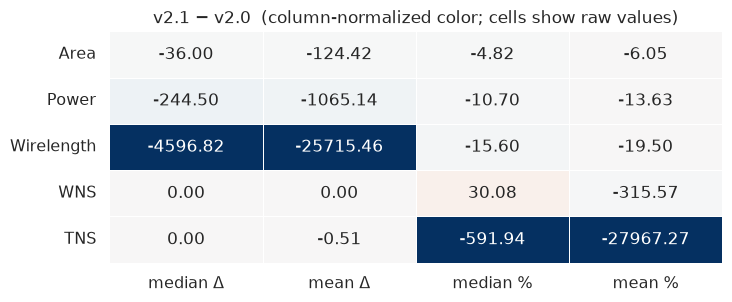

Verdicts (median over 36 pairs):
  Area: improve  (median -4.8%)
  Power: improve  (median -10.7%)
  Wirelength: improve  (median -15.6%)
  WNS: improve  (median Δ +0.0022)
  TNS: flat  (median Δ +0.0000)
  TCP (context): retarget  (median -8.2%)


In [7]:
COMPARE = [
    ("total_area", "Area", "lower"),
    ("total_power", "Power", "lower"),
    ("net_length", "Wirelength", "lower"),
    ("worst_slack", "WNS", "higher"),
    ("total_negative_slack", "TNS", "higher"),
    ("clock_period", "TCP (context)", "context"),
]

rows = []
for m, lab, better in COMPARE:
    abs_d = cmp[f"v21_{m}"] - cmp[f"v20_{m}"]
    pct = 100.0 * abs_d / cmp[f"v20_{m}"].abs().replace(0, np.nan)
    med_abs, med_pct = abs_d.median(), pct.median()
    if better == "lower":
        if med_pct < -1:
            verdict = "improve"
        elif med_pct > 1:
            verdict = "degrade"
        else:
            verdict = "flat"
    elif better == "higher":
        if med_abs > 1e-3:
            verdict = "improve"
        elif med_abs < -1e-3:
            verdict = "degrade"
        else:
            verdict = "flat"
    else:
        verdict = "retarget" if abs(med_pct) > 1 else "matched"
    rows.append({
        "metric": lab,
        "better": better,
        "verdict": verdict,
        "median_Δ": med_abs,
        "mean_Δ": abs_d.mean(),
        "std_Δ": abs_d.std(ddof=0),
        "min_Δ": abs_d.min(),
        "max_Δ": abs_d.max(),
        "median_%": med_pct,
        "mean_%": pct.mean(),
        "std_%": pct.std(ddof=0),
        "min_%": pct.min(),
        "max_%": pct.max(),
        "n": int(abs_d.notna().sum()),
    })
summary = pd.DataFrame(rows)
show = summary.copy()
for c in ["median_Δ", "mean_Δ", "std_Δ", "min_Δ", "max_Δ",
          "median_%", "mean_%", "std_%", "min_%", "max_%"]:
    show[c] = show[c].astype(float).round(3)
display(show)
summary.to_csv(RESULTS / f"{PDK}_v20_vs_v21_orfs_shift.csv", index=False)

# per-design mean of BP/BF for strip distribution
per_design = []
for design, g in cmp.groupby("design"):
    rec = {"design": design}
    for m, lab, _ in COMPARE:
        abs_d = g[f"v21_{m}"] - g[f"v20_{m}"]
        pct = 100.0 * abs_d / g[f"v20_{m}"].abs().replace(0, np.nan)
        rec[f"{m}_abs"] = abs_d.mean()
        rec[f"{m}_pct"] = pct.mean()
    per_design.append(rec)
per_design = pd.DataFrame(per_design)
per_design.to_csv(RESULTS / f"{PDK}_v20_vs_v21_per_design.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plot_specs = [
    ("total_area_pct", "Area Δ%"),
    ("total_power_pct", "Power Δ%"),
    ("net_length_pct", "Wirelength Δ%"),
    ("worst_slack_abs", "WNS Δ (ns)"),
    ("total_negative_slack_abs", "TNS Δ (ns)"),
    ("clock_period_pct", "TCP Δ% (context)"),
]
for ax, (col, ylabel) in zip(axes.ravel(), plot_specs):
    s = per_design[col].dropna()
    sns.stripplot(y=s, ax=ax, size=7, color="#4c72b0")
    if len(s):
        ax.axhline(s.median(), color="black", linewidth=2, label="median")
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.set_xticks([])
    ax.set_title(ylabel)
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_v20_vs_v21_delta_dist.png", dpi=200, bbox_inches="tight")
plt.show()

core = summary[summary.metric != "TCP (context)"].set_index("metric")
heat = core[["median_Δ", "mean_Δ", "median_%", "mean_%"]].astype(float)
heat.columns = ["median Δ", "mean Δ", "median %", "mean %"]
# color each column independently so abs and % scales do not fight
color = heat.apply(lambda s: s / s.abs().max() if s.abs().max() else s, axis=0)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
sns.heatmap(color, ax=ax, cmap="RdBu_r", center=0, annot=heat,
            fmt=".2f", cbar=False, linewidths=0.5, linecolor="white")
ax.set_title("v2.1 − v2.0  (column-normalized color; cells show raw values)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(RESULTS / f"{PDK}_v20_vs_v21_delta_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

print("Verdicts (median over 36 pairs):")
for _, r in summary.iterrows():
    if r["metric"] == "TCP (context)":
        print(f"  {r['metric']}: {r['verdict']}  (median {r['median_%']:.1f}%)")
    elif r["better"] == "higher":
        print(f"  {r['metric']}: {r['verdict']}  (median Δ {r['median_Δ']:+.4f})")
    else:
        print(f"  {r['metric']}: {r['verdict']}  (median {r['median_%']:+.1f}%)")


## How OpenROAD v2.1 compares on this PDK

Pooled over all 36 BP/BF pairs at `final` for **ASAP7 7nm (ASAP7)** (ORFS `a50fb65` → `c2c8aee`).

- ASAP7 SDC periods are picoseconds; this notebook converts v2.1 TCP to ns before comparing. After conversion, median TCP is ~8% tighter.
- **Area** improves (median −4.8%). **Wirelength** improves (median −16%). **Power** degrades (median +17%).
- **WNS / TNS** stay near the closure boundary with labels intact: BP clean, BF violating (18/18). Early dumps used the wrong ASAP7 liberty corner in postprocess (FF vs ORFS TT) and looked falsely clean — current dump matches finish.
- Net: physical metrics move under a slightly tighter clock; timing labels match the BPBF definition.
